# Notebook 04 – Giải thích mô hình bằng SHAP (bảng T10, T11 và hình)
Notebook này **không viết lại** logic làm sạch hay huấn luyện: nó gọi `clean`, `lay_ban` (cleaning.py), `modeling.py` (danh sách đặc trưng, tham số mô hình), `explain.py` (SHAP), `plot_shap.py` (vẽ hình) và `model_io.py` (lưu mô hình).

**SHAP là gì (nói đơn giản):** với **mỗi người**, SHAP cho biết từng câu hỏi đã đẩy dự đoán của mô hình **lên** hay **xuống** bao nhiêu so với mức trung bình. Cộng tất cả lại thì ra đúng dự đoán của mô hình (ta kiểm tra điều này ở mục A).

**Lưu ý quan trọng:** SHAP mô tả *cách mô hình dự đoán*, **không** phải nguyên nhân thật. Biến đầu ra vẫn là năng lực sáng tạo **tự nhận thức** (C1–C5 tự chấm).

**Quy tắc (đã kiểm tra bằng code):** dùng đúng danh sách đặc trưng và hàm kiểm tra cột cấm của `modeling.py`; dữ liệu là bản chính 297 (khóa `chat`); `random_state = 42`; B4_3, B4_6 giữ số gốc 1–5 (không đảo); tên biến trên hình là nhãn tiếng Việt ngắn (`content/feature_labels.json`).

## 1. Nạp dữ liệu và chuẩn bị

In [1]:
import sys; sys.path.append('../src')
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from scipy.stats import spearmanr
from sklearn.metrics import f1_score
import shap, xgboost, sklearn          # nếu dòng này lỗi: chạy  pip install shap
from sparkmind import config, modeling as M, explain as E, model_io as IO
from sparkmind.cleaning import clean, lay_ban
from sparkmind.loaders import doc_excel, doc_goc_mongo
from sparkmind.db import lay_db
from sparkmind.plot_shap import ve_cot_ngang, ve_beeswarm, ve_phu_thuoc

NGUON = 'excel'   # đổi thành 'mongo' khi dữ liệu đã nằm trong MongoDB
raw = doc_excel() if NGUON == 'excel' else doc_goc_mongo(lay_db())
sach = clean(raw)   # gắn cờ chất lượng, không xóa form nào
BANG = config.ROOT / 'outputs' / 'tables'; HINH = config.ROOT / 'outputs' / 'figures'; MODELS = config.ROOT / 'models'
for p in (BANG, HINH, MODELS): p.mkdir(parents=True, exist_ok=True)

def luu(bang, ten, hien=True):
    """Lưu bảng CSV (UTF-8 có BOM để Excel đọc được tiếng Việt) rồi hiện ra (làm tròn 3 số lẻ)."""
    bang.to_csv(BANG / ten, index=False, encoding='utf-8-sig')
    if hien: display(bang.round(3))

CHINH = config.BAN_CHINH                      # bản chính của báo cáo = 'chat' (297)
ban = lay_ban(sach, CHINH).reset_index(drop=True)
assert CHINH == 'chat' and len(ban) == 297
X = M.tao_dac_trung(ban)                      # đã kiểm tra cột cấm bên trong
y_lop, y_diem = M.tao_nhan(ban)
NHAN = E.doc_nhan()                           # nhãn tiếng Việt ngắn
print('Bản chính 297 dòng,', X.shape[1], 'đặc trưng. shap', shap.__version__, '| xgboost', xgboost.__version__, '| sklearn', sklearn.__version__)

Bản chính 297 dòng, 35 đặc trưng. shap 0.54.1 | xgboost 3.4.1 | sklearn 1.9.1


## A. Huấn luyện bốn mô hình cuối và kiểm tra SHAP
**Làm gì:** huấn luyện trên **toàn bộ 297 người** (để giải thích; đây không phải để đo độ chính xác). Bốn mô hình, cùng tham số như notebook 03: Random Forest và XGBoost phân loại 3 mức; Random Forest và XGBoost hồi quy điểm 0–100.

**Hai kiểm tra bắt buộc (nếu lệch thì code báo lỗi dừng):**
1. **Tính cộng:** tổng SHAP của các biến + giá trị nền = đầu ra mô hình (margin với XGBoost phân loại, xác suất với RF phân loại, điểm dự đoán với hồi quy).
2. **pred_contribs:** SHAP của `TreeExplainer` phải trùng với `pred_contribs` của chính XGBoost (cách server sẽ giải thích từng người dùng).

**Lưu ý đọc số:** macro-F1 *trên chính dữ liệu huấn luyện* sẽ cao (mô hình đã thấy đáp án), chỉ in để xem, **không dùng để báo cáo**. Số đáng tin là macro-F1 của kiểm định chéo (CV 5×10) ở notebook 03 (bảng T6).

In [2]:
kq = E.huan_luyen_cuoi(X, y_lop, y_diem)      # bốn mô hình, huấn luyện trên toàn bản chính 297
MH, Xm, TX = kq['mo_hinh'], kq['X_mh'], kq['tien_xu_ly']
COT = list(Xm.columns)                        # 37 cột sau one-hot (cap_hoc thành 3 cột)
SHAP = {ten: E.tinh_shap(m, Xm) for ten, m in MH.items()}   # {tên: (giá trị SHAP, giá trị nền)}

# macro-F1: CV (notebook 03, T6) để đối chiếu, và macro-F1 trên chính dữ liệu huấn luyện (chỉ để xem)
t6 = pd.read_csv(BANG / 'T6_cv_classification_strict.csv').set_index('mo_hinh')['macro_f1_tb']
ten_t6 = {'xgb_clf': 'XGBoost', 'rf_clf': 'Random Forest'}
f1 = pd.DataFrame({'macro_F1_CV_5x10 (T6, đáng tin)': [t6[v] for v in ten_t6.values()],
                   'macro_F1_trên_dữ_liệu_huấn_luyện (chỉ xem)': [f1_score(y_lop, MH[k].predict(Xm), average='macro') for k in ten_t6]},
                  index=list(ten_t6.values()))
display(f1.round(3))

,"macro_F1_CV_5x10 (T6, đáng tin)",macro_F1_trên_dữ_liệu_huấn_luyện (chỉ xem)
XGBoost,0.628,0.983
Random Forest,0.659,0.949


In [3]:
# Kiểm tra tính cộng và pred_contribs. Hàm báo lỗi (AssertionError) nếu lệch quá ngưỡng.
dong = []
for ten, m in MH.items():
    sv, nen = SHAP[ten]
    lech_cong = E.kiem_tra_cong(m, Xm, sv, nen, ten)
    lech_pc = E.doi_chieu_pred_contribs(m, Xm, sv, nen, ten) if ten.startswith('xgb') else np.nan
    dong.append({'mo_hinh': ten, 'dau_ra_duoc_giai_thich': 'margin' if ten == 'xgb_clf' else 'xác suất' if ten == 'rf_clf' else 'điểm 0–100',
                 'lech_cong_toi_da': lech_cong, 'nguong_cho_phep': E.dung_sai_cong(m, Xm), 'lech_pred_contribs_toi_da': lech_pc})
kt = pd.DataFrame(dong)
luu(kt.assign(lech_cong_toi_da=kt['lech_cong_toi_da'].map('{:.2e}'.format), nguong_cho_phep=kt['nguong_cho_phep'].map('{:.1e}'.format),
              lech_pred_contribs_toi_da=kt['lech_pred_contribs_toi_da'].map('{:.2e}'.format)), 'T10_shap_checks_strict.csv')
print('Cả bốn mô hình đều cộng đúng; XGBoost trùng pred_contribs.')

,mo_hinh,dau_ra_duoc_giai_thich,lech_cong_toi_da,nguong_cho_phep,lech_pred_contribs_toi_da
0,xgb_clf,margin,3.00e-06,1.0e-04,0.00e+00
1,rf_clf,xác suất,2.55e-15,1.0e-04,nan
2,xgb_reg,điểm 0–100,1.01e-04,9.4e-04,0.00e+00
3,rf_reg,điểm 0–100,1.35e-13,8.9e-04,nan


Cả bốn mô hình đều cộng đúng; XGBoost trùng pred_contribs.


## B. Tầm quan trọng toàn cục (bảng T10)
**Cách tính:** với mỗi biến, lấy trung bình của |SHAP| trên 297 người. Càng lớn = biến đó càng làm dự đoán thay đổi nhiều (không nói biến đó tăng hay giảm điểm; chiều tác động xem mục C).
- Phân loại: tính riêng cho từng mức (Thấp, Trung bình, Cao) và **gộp = trung bình của ba mức**.
- Cấp học được one-hot thành 3 cột; ở đây đã **cộng SHAP 3 cột lại** thành một biến "Cấp học".
- **Lưu ý khi so RF với XGBoost:** thang đo khác nhau (XGBoost tính theo margin, RF theo xác suất) nên **chỉ so thứ hạng, không so độ lớn**.

In [4]:
def bang_quan_trong(ten, cot_diem):
    d = E.them_hang(E.do_quan_trong(SHAP[ten][0], COT), cot_diem)
    d.insert(1, 'ten_bien', d['bien'].map(NHAN)); d.insert(0, 'mo_hinh', ten)
    return d

QT = {k: bang_quan_trong(k, 'gop') for k in ('xgb_clf', 'rf_clf')} | {k: bang_quan_trong(k, 'tb_abs_shap') for k in ('xgb_reg', 'rf_reg')}
t10_clf = pd.concat([QT['xgb_clf'], QT['rf_clf']], ignore_index=True)
t10_reg = pd.concat([QT['xgb_reg'], QT['rf_reg']], ignore_index=True)
print('T10 phân loại (XGBoost và RF, mỗi mô hình 35 biến; cột hang = hạng theo cột gop):')
luu(t10_clf, 'T10_shap_importance_clf_strict.csv', hien=False)
luu(t10_reg, 'T10_shap_importance_reg_strict.csv', hien=False)
print('XGBoost phân loại, 15 biến đầu:'); display(QT['xgb_clf'].head(15).round(3))
print('Random Forest phân loại, 15 biến đầu:'); display(QT['rf_clf'].head(15).round(3))
print('Hồi quy XGBoost, 15 biến đầu:'); display(QT['xgb_reg'].head(15).round(3))
print('Hồi quy Random Forest, 15 biến đầu:'); display(QT['rf_reg'].head(15).round(3))

T10 phân loại (XGBoost và RF, mỗi mô hình 35 biến; cột hang = hạng theo cột gop):
XGBoost phân loại, 15 biến đầu:


,mo_hinh,bien,ten_bien,Thap,Trung_binh,Cao,gop,hang
0,xgb_clf,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",0.586,0.181,0.473,0.413,1
1,xgb_clf,B4_3,Dùng ngay không kiểm tra (B4_3),0.323,0.117,0.633,0.358,2
2,xgb_clf,B4_7,Dùng AI tìm ý tưởng mới (B4_7),0.292,0.074,0.434,0.267,3
3,xgb_clf,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),0.090,0.089,0.561,0.247,4
4,xgb_clf,B4_1,Chỉnh prompt nhiều lần (B4_1),0.247,0.166,0.308,0.240,5
5,xgb_clf,B4_2,Hỏi AI 'tại sao' (B4_2),0.344,0.045,0.293,0.228,6
6,xgb_clf,lop_so,Lớp (6–16),0.245,0.093,0.202,0.180,7
7,xgb_clf,B4_5,Không có AI vẫn làm tốt (B4_5),0.138,0.105,0.255,0.166,8
8,xgb_clf,B3_so,Số mục đích dùng AI,0.106,0.215,0.130,0.150,9
9,xgb_clf,B3_tom_tat,Mục đích: tóm tắt,0.038,0.104,0.256,0.133,10


Random Forest phân loại, 15 biến đầu:


,mo_hinh,bien,ten_bien,Thap,Trung_binh,Cao,gop,hang
0,rf_clf,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",0.061,0.032,0.043,0.045,1
1,rf_clf,B4_7,Dùng AI tìm ý tưởng mới (B4_7),0.051,0.027,0.051,0.043,2
2,rf_clf,B4_3,Dùng ngay không kiểm tra (B4_3),0.029,0.035,0.061,0.042,3
3,rf_clf,B4_2,Hỏi AI 'tại sao' (B4_2),0.058,0.021,0.041,0.040,4
4,rf_clf,B4_1,Chỉnh prompt nhiều lần (B4_1),0.042,0.026,0.023,0.031,5
5,rf_clf,B4_5,Không có AI vẫn làm tốt (B4_5),0.029,0.016,0.039,0.028,6
6,rf_clf,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),0.024,0.014,0.035,0.024,7
7,rf_clf,lop_so,Lớp (6–16),0.022,0.011,0.019,0.017,8
8,rf_clf,B3_so,Số mục đích dùng AI,0.008,0.015,0.008,0.010,9
9,rf_clf,B6_so,Số cách đặt prompt,0.012,0.011,0.007,0.010,10


Hồi quy XGBoost, 15 biến đầu:


,mo_hinh,bien,ten_bien,tb_abs_shap,hang
0,xgb_reg,B4_2,Hỏi AI 'tại sao' (B4_2),3.865,1
1,xgb_reg,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",3.335,2
2,xgb_reg,B4_7,Dùng AI tìm ý tưởng mới (B4_7),3.079,3
3,xgb_reg,B4_3,Dùng ngay không kiểm tra (B4_3),2.710,4
4,xgb_reg,B4_1,Chỉnh prompt nhiều lần (B4_1),2.324,5
5,xgb_reg,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),1.752,6
6,xgb_reg,B4_5,Không có AI vẫn làm tốt (B4_5),1.740,7
7,xgb_reg,B3_so,Số mục đích dùng AI,1.248,8
8,xgb_reg,B7_tiep_tuc,Sau đó: nhập tiếp để chỉnh,1.052,9
9,xgb_reg,B3_tom_tat,Mục đích: tóm tắt,1.027,10


Hồi quy Random Forest, 15 biến đầu:


,mo_hinh,bien,ten_bien,tb_abs_shap,hang
0,rf_reg,B4_2,Hỏi AI 'tại sao' (B4_2),4.631,1
1,rf_reg,B4_7,Dùng AI tìm ý tưởng mới (B4_7),2.919,2
2,rf_reg,B4_3,Dùng ngay không kiểm tra (B4_3),2.847,3
3,rf_reg,B4_1,Chỉnh prompt nhiều lần (B4_1),2.608,4
4,rf_reg,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",2.205,5
5,rf_reg,B4_5,Không có AI vẫn làm tốt (B4_5),1.792,6
6,rf_reg,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),1.044,7
7,rf_reg,lop_so,Lớp (6–16),0.646,8
8,rf_reg,B7_tiep_tuc,Sau đó: nhập tiếp để chỉnh,0.425,9
9,rf_reg,B7_doi_chieu,Sau đó: đối chiếu nguồn khác,0.364,10


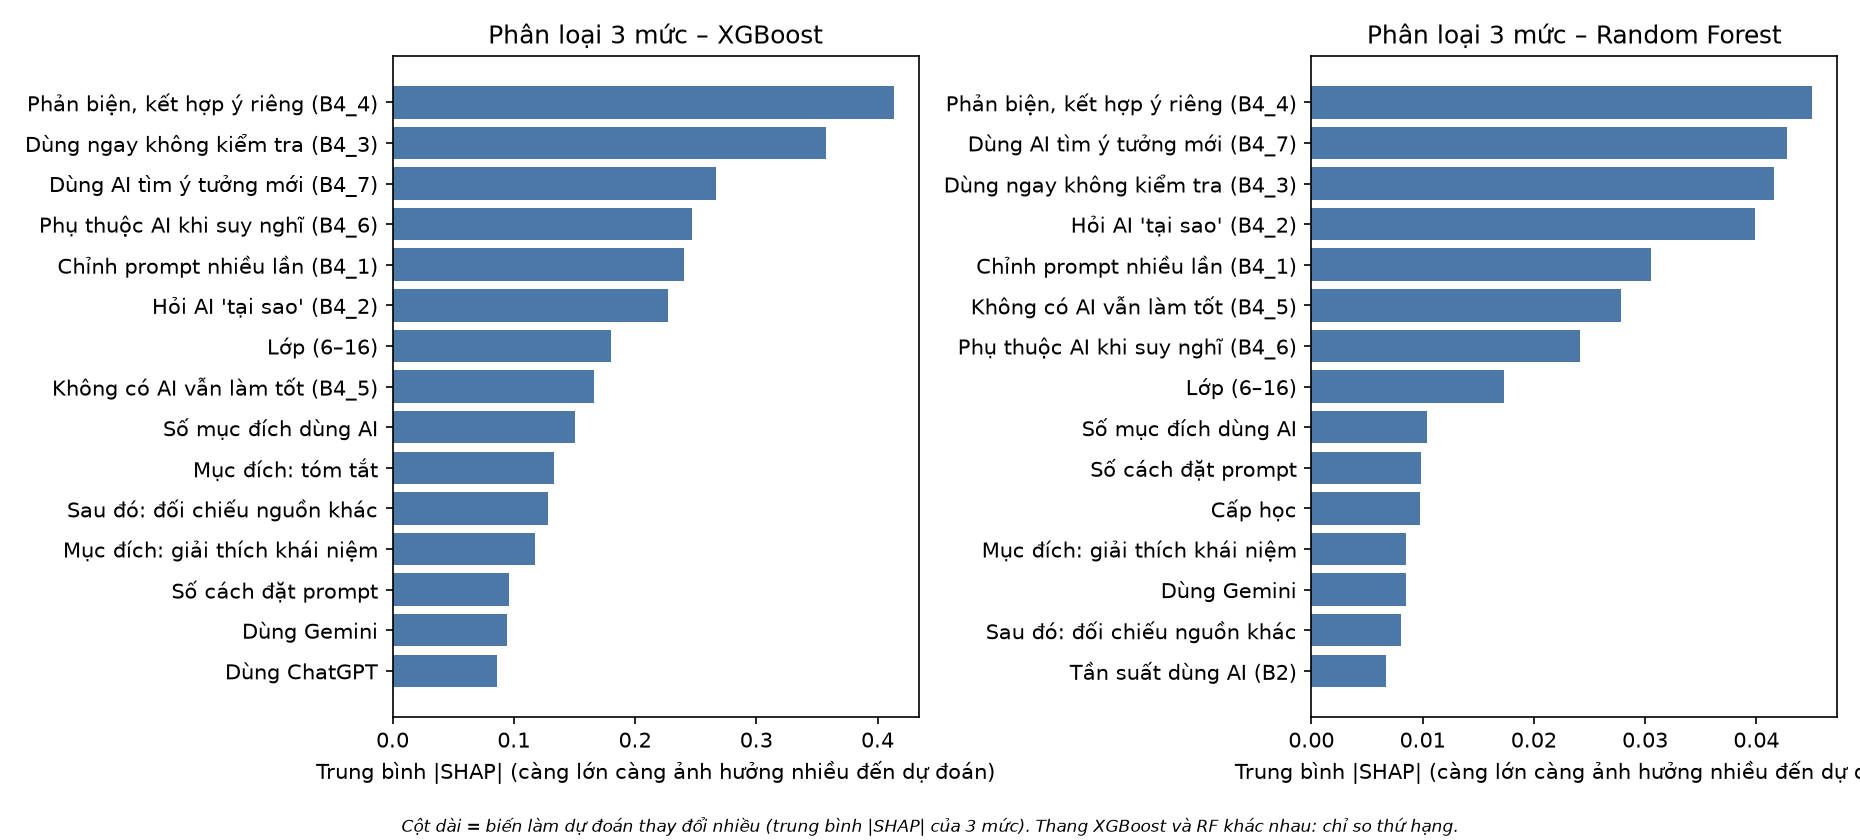

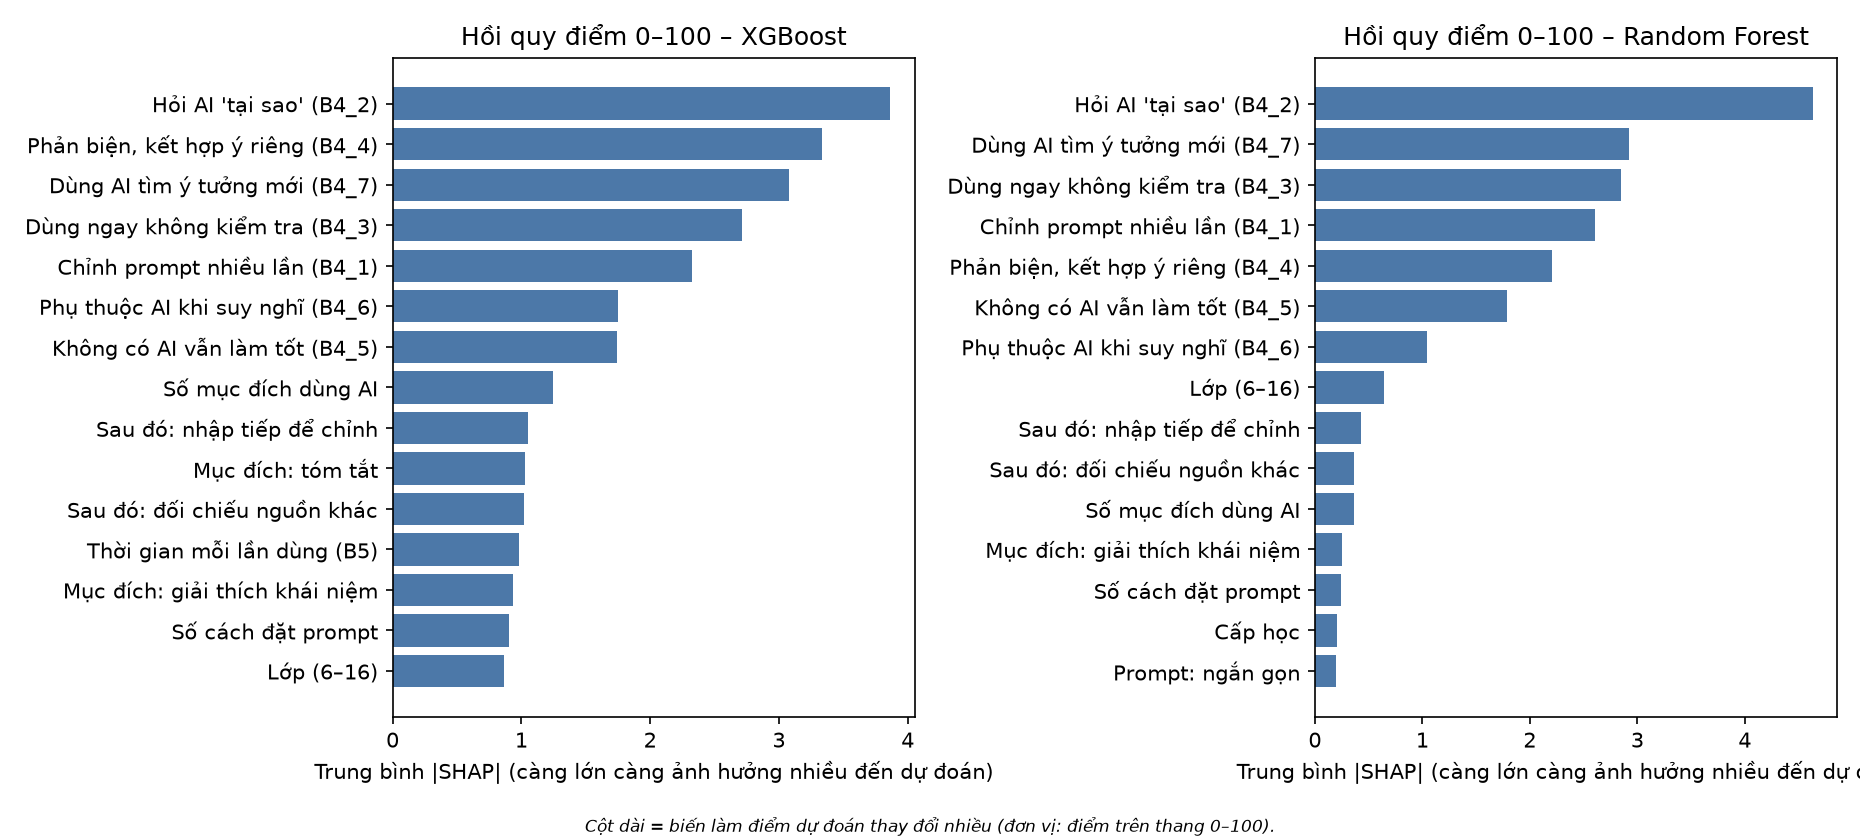

In [5]:
ve_cot_ngang([('Phân loại 3 mức – XGBoost', QT['xgb_clf'], 'gop'), ('Phân loại 3 mức – Random Forest', QT['rf_clf'], 'gop')], NHAN,
            'Cột dài = biến làm dự đoán thay đổi nhiều (trung bình |SHAP| của 3 mức). Thang XGBoost và RF khác nhau: chỉ so thứ hạng.',
            HINH / 'fig_shap_bar_clf_strict.png')
ve_cot_ngang([('Hồi quy điểm 0–100 – XGBoost', QT['xgb_reg'], 'tb_abs_shap'), ('Hồi quy điểm 0–100 – Random Forest', QT['rf_reg'], 'tb_abs_shap')], NHAN,
            'Cột dài = biến làm điểm dự đoán thay đổi nhiều (đơn vị: điểm trên thang 0–100).',
            HINH / 'fig_shap_bar_reg_strict.png')
display(Image(HINH / 'fig_shap_bar_clf_strict.png')); display(Image(HINH / 'fig_shap_bar_reg_strict.png'))

## C. Chiều tác động (beeswarm và biểu đồ phụ thuộc)
**Cách đọc beeswarm:** mỗi chấm là một người. Chấm nằm bên **phải** (SHAP dương) = biến đó đẩy dự đoán **lên** cho người ấy; bên **trái** = đẩy xuống. Màu: đỏ = giá trị biến cao, xanh = thấp (giá trị **gốc**, B4 từ 1 đến 5, **không đảo chiều**).
Hình dưới dùng XGBoost phân loại (mức Cao và mức Thấp) và XGBoost hồi quy.

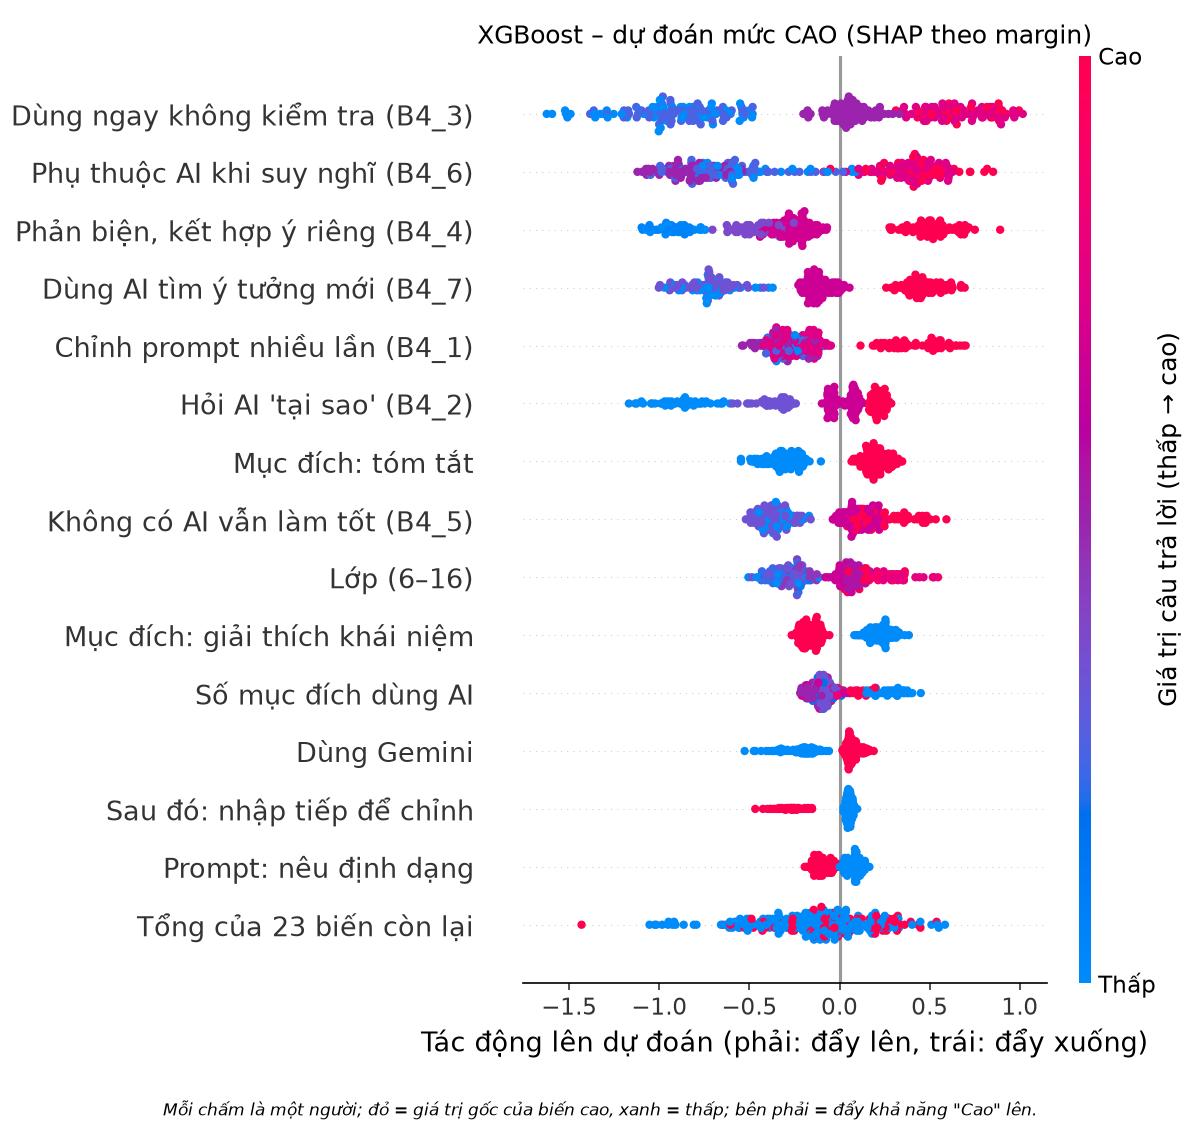

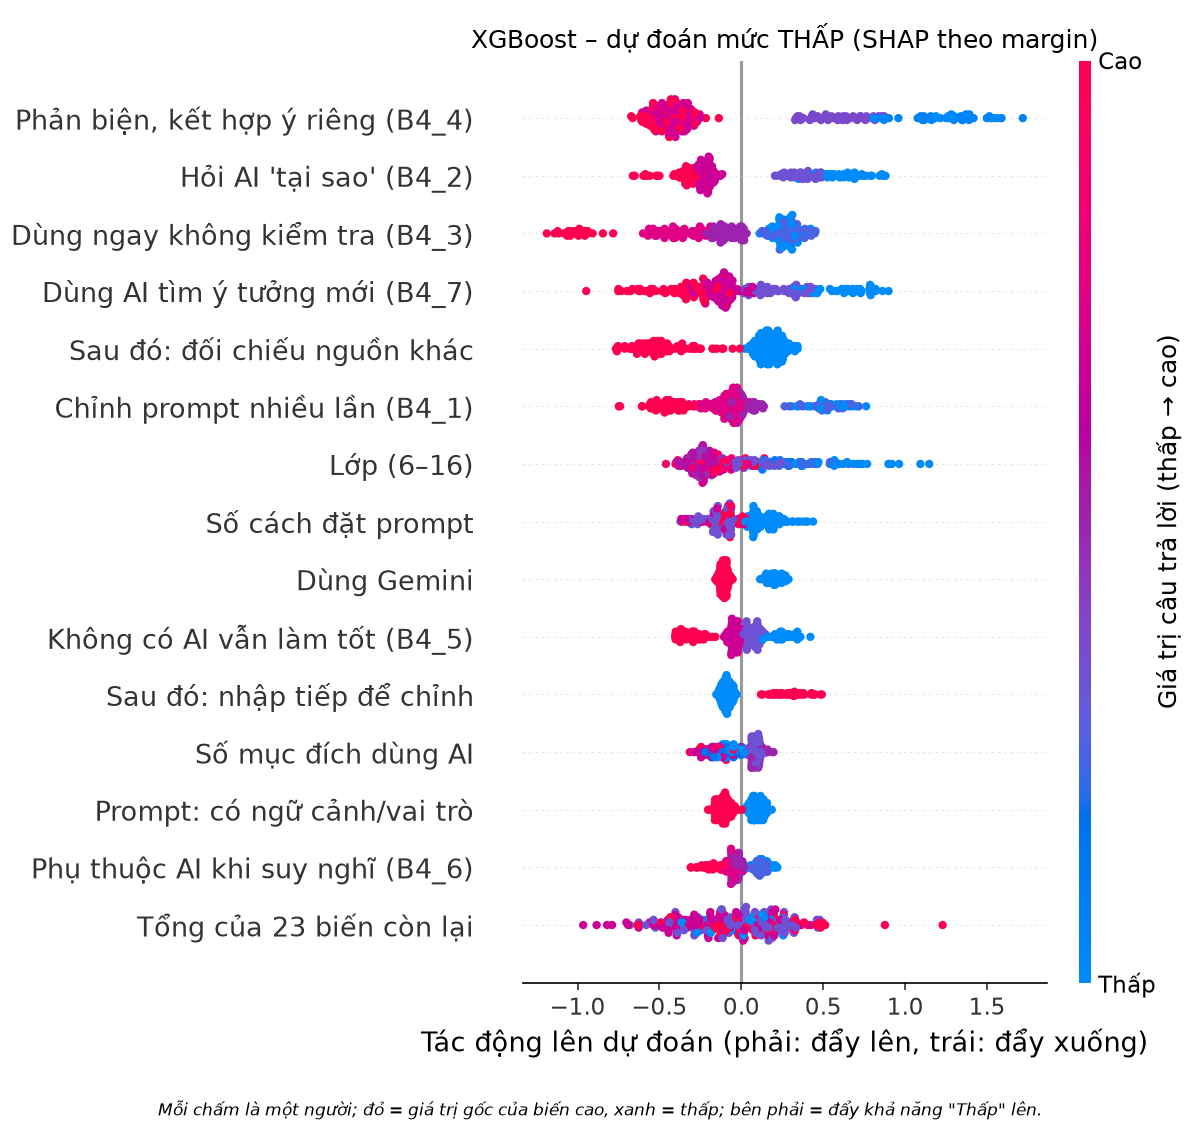

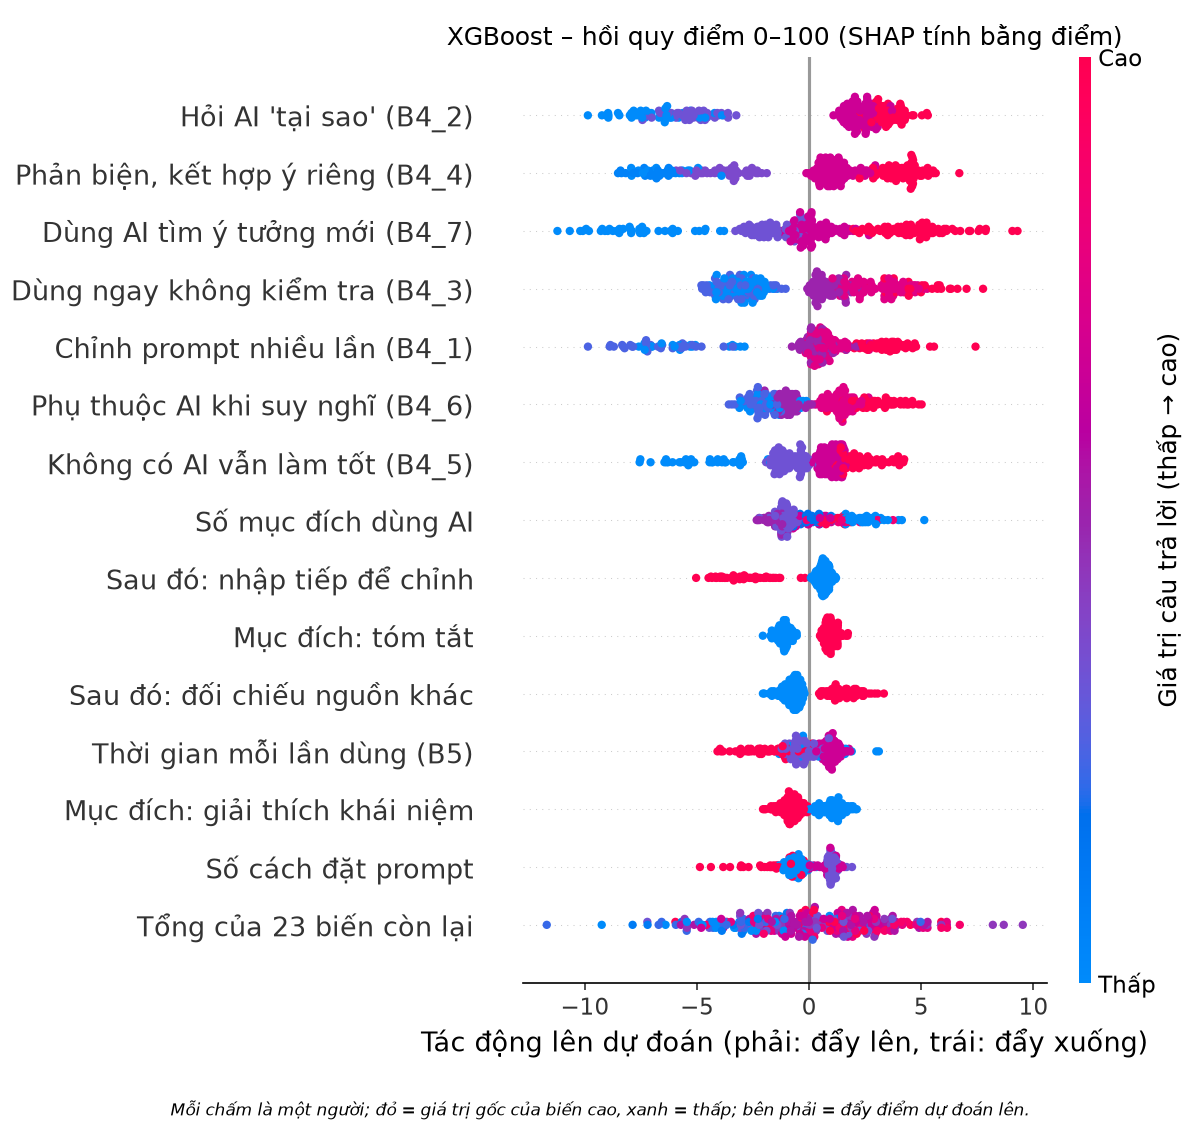

In [6]:
sv_clf = SHAP['xgb_clf'][0]; sv_reg = SHAP['xgb_reg'][0]
ve_beeswarm(sv_clf[:, :, 2], Xm, NHAN, 'XGBoost – dự đoán mức CAO (SHAP theo margin)',
            'Mỗi chấm là một người; đỏ = giá trị gốc của biến cao, xanh = thấp; bên phải = đẩy khả năng "Cao" lên.',
            HINH / 'fig_shap_beeswarm_cao_strict.png')
ve_beeswarm(sv_clf[:, :, 0], Xm, NHAN, 'XGBoost – dự đoán mức THẤP (SHAP theo margin)',
            'Mỗi chấm là một người; đỏ = giá trị gốc của biến cao, xanh = thấp; bên phải = đẩy khả năng "Thấp" lên.',
            HINH / 'fig_shap_beeswarm_thap_strict.png')
ve_beeswarm(sv_reg, Xm, NHAN, 'XGBoost – hồi quy điểm 0–100 (SHAP tính bằng điểm)',
            'Mỗi chấm là một người; đỏ = giá trị gốc của biến cao, xanh = thấp; bên phải = đẩy điểm dự đoán lên.',
            HINH / 'fig_shap_beeswarm_reg_strict.png')
for f in ('cao', 'thap', 'reg'): display(Image(HINH / f'fig_shap_beeswarm_{f}_strict.png'))

3 biến quan trọng nhất (XGBoost phân loại): ['B4_4', 'B4_3', 'B4_7']


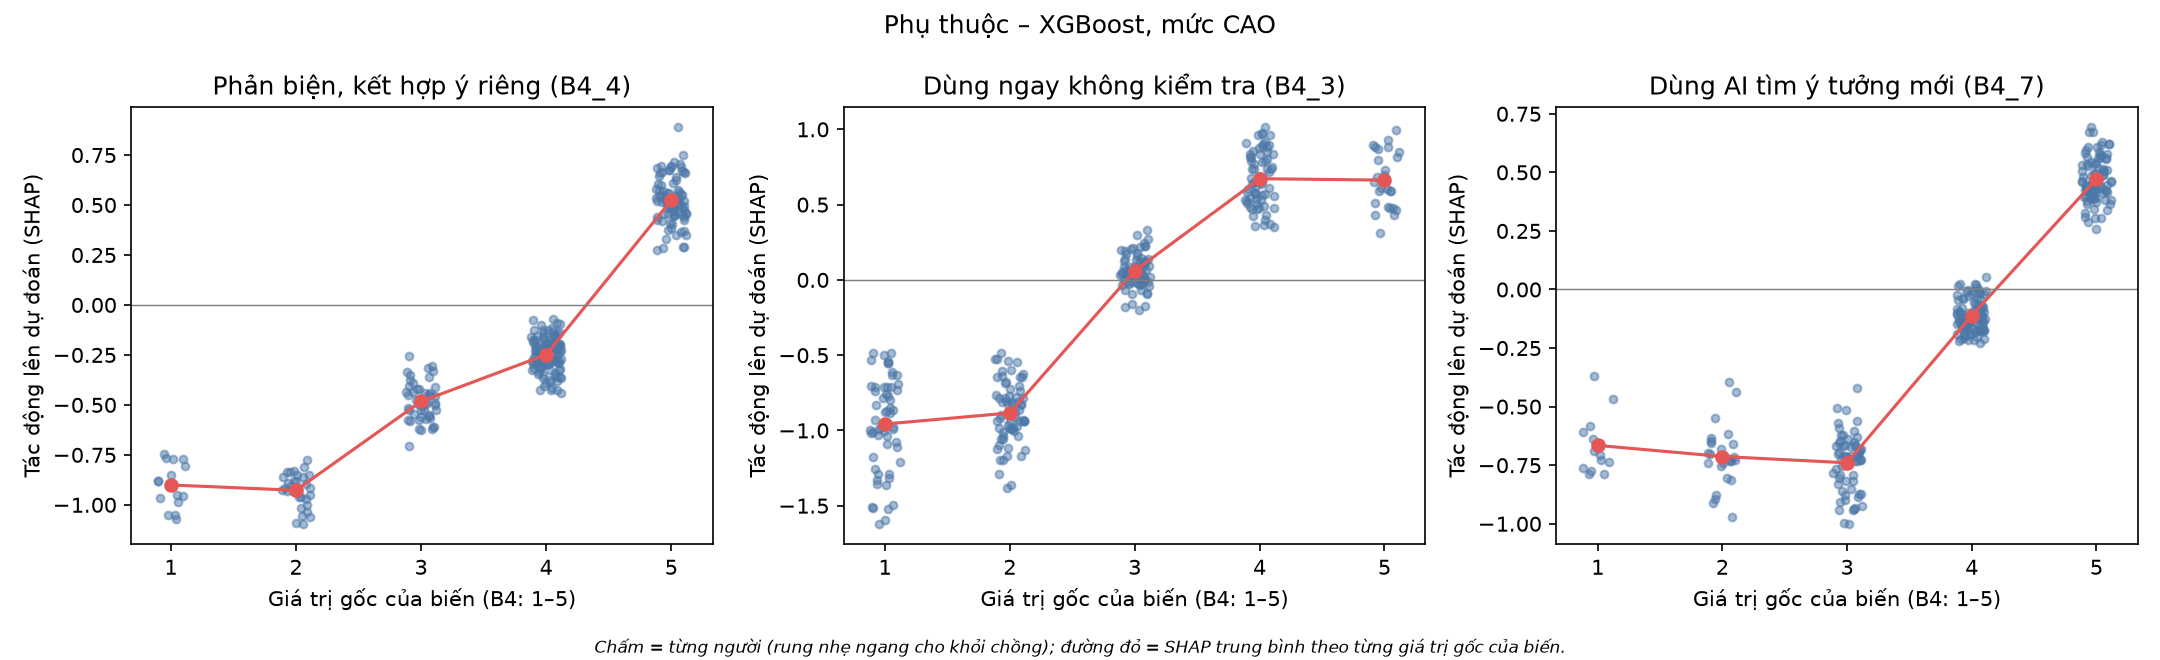

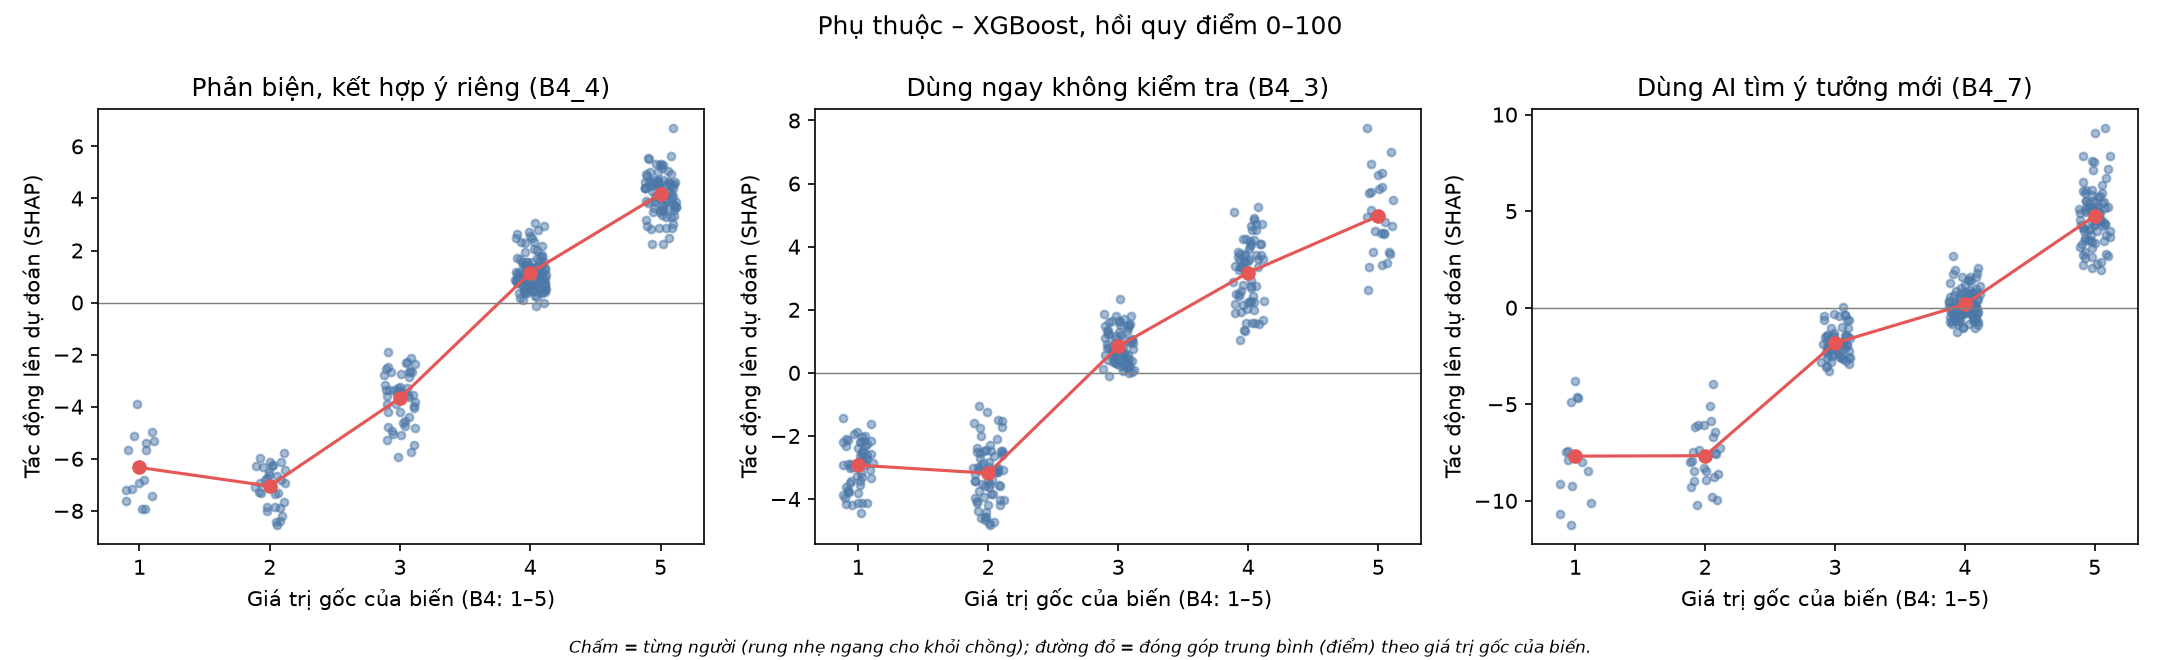

In [7]:
# Biểu đồ phụ thuộc cho 3 biến quan trọng nhất (theo XGBoost phân loại, cột gop; chỉ lấy biến gốc, không lấy cột one-hot)
top3 = [b for b in QT['xgb_clf']['bien'] if b != 'cap_hoc'][:3]
print('3 biến quan trọng nhất (XGBoost phân loại):', top3)
ve_phu_thuoc(sv_clf[:, :, 2], Xm, top3, NHAN, 'Phụ thuộc – XGBoost, mức CAO',
             'Chấm = từng người (rung nhẹ ngang cho khỏi chồng); đường đỏ = SHAP trung bình theo từng giá trị gốc của biến.',
             HINH / 'fig_shap_dependence_cao_strict.png')
ve_phu_thuoc(sv_reg, Xm, top3, NHAN, 'Phụ thuộc – XGBoost, hồi quy điểm 0–100',
             'Chấm = từng người (rung nhẹ ngang cho khỏi chồng); đường đỏ = đóng góp trung bình (điểm) theo giá trị gốc của biến.',
             HINH / 'fig_shap_dependence_reg_strict.png')
display(Image(HINH / 'fig_shap_dependence_cao_strict.png')); display(Image(HINH / 'fig_shap_dependence_reg_strict.png'))

In [8]:
# Chiều tác động bằng số: Spearman giữa GIÁ TRỊ GỐC của biến và SHAP của nó (dương = giá trị càng cao càng đẩy lên).
# Dùng cho 7 câu B4 (số gốc 1–5, không đảo). Đây là số bổ sung để chắc chắn khi đọc hình; không phải kiểm định.
dong = []
for b in M.B4:
    i = COT.index(b); r = {'bien': b, 'ten_bien': NHAN[b]}
    for k, m in enumerate(M.MUC_THU_TU): r[f'rho_gia_tri_SHAP_{m}'] = spearmanr(Xm[b], sv_clf[:, i, k])[0]
    r['rho_gia_tri_SHAP_hoi_quy'] = spearmanr(Xm[b], sv_reg[:, i])[0]
    dong.append(r)
luu(pd.DataFrame(dong), 'T10_shap_direction_B4_strict.csv')

,bien,ten_bien,rho_gia_tri_SHAP_Thap,rho_gia_tri_SHAP_Trung_binh,rho_gia_tri_SHAP_Cao,rho_gia_tri_SHAP_hoi_quy
0,B4_1,Chỉnh prompt nhiều lần (B4_1),-0.929,0.381,0.708,0.872
1,B4_2,Hỏi AI 'tại sao' (B4_2),-0.930,-0.580,0.952,0.930
2,B4_3,Dùng ngay không kiểm tra (B4_3),-0.895,-0.722,0.900,0.895
3,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",-0.749,-0.418,0.944,0.948
4,B4_5,Không có AI vẫn làm tốt (B4_5),-0.954,-0.151,0.848,0.951
5,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),-0.917,0.443,0.685,0.924
6,B4_7,Dùng AI tìm ý tưởng mới (B4_7),-0.907,-0.638,0.921,0.947


## D. Độ ổn định của kết quả SHAP
Mẫu chỉ 297 người, nên cần hỏi: *thứ hạng các biến có ổn định không?*
- **(i)** Huấn luyện lại trên từng fold của CV lặp 5×10 (đúng 50 lần chia như T6), tính |SHAP| **trên phần thử** của fold, rồi xem hạng của từng biến thay đổi thế nào (trung bình và khoảng 2.5%–97.5%) → bảng **T11**. Làm cho XGBoost và Random Forest phân loại.
- **(ii)** Huấn luyện **riêng** trên đợt 2 và **riêng** trên đợt 3, so thứ hạng biến bằng hệ số Spearman. (Đợt 1 chỉ có 31 người nên bỏ.) |SHAP| ở đây tính trên chính dữ liệu của đợt đó.
- **(iii)** So thứ hạng giữa XGBoost và Random Forest (mô hình cuối).

**Cách đọc Spearman:** gần 1 = hai thứ hạng giống nhau; gần 0 = không liên quan. Spearman tính trên 35 biến, gồm nhiều biến gần như không có tác động (hạng của chúng gần như ngẫu nhiên), nên hệ số này thường **thấp hơn** cảm nhận về "các biến đầu giống nhau". Vì vậy dưới đây có thêm số biến trùng nhau trong top 10.

In [9]:
import time; t0 = time.time()
chia = M.tao_cac_lan_chia(y_lop)            # đúng 50 lần chia như T6 (random_state = 42)
assert len(chia) == 50
tom = []
for ten in ('xgb_clf', 'rf_clf'):
    bf = E.shap_theo_fold(X, y_lop, chia, ten)
    tom.append(E.tom_tat_hang(bf).assign(mo_hinh=ten))
t11 = pd.concat(tom, ignore_index=True)
t11.insert(1, 'ten_bien', t11['bien'].map(NHAN))
luu(t11, 'T11_shap_rank_stability_strict.csv', hien=False)
print(f'Xong 2 x 50 lần huấn luyện lại trong {time.time()-t0:.0f} giây. 15 biến đầu mỗi mô hình (hạng 1 = quan trọng nhất):')
for ten in ('xgb_clf', 'rf_clf'):
    print(ten); display(t11[t11.mo_hinh == ten].head(15).round(3))

Xong 2 x 50 lần huấn luyện lại trong 49 giây. 15 biến đầu mỗi mô hình (hạng 1 = quan trọng nhất):
xgb_clf


,bien,ten_bien,tb_abs_shap,hang_tb,hang_p2_5,hang_p97_5,ty_le_top10,mo_hinh
0,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",0.387,1.44,1.000,3.000,1.00,xgb_clf
1,B4_3,Dùng ngay không kiểm tra (B4_3),0.373,1.86,1.000,3.000,1.00,xgb_clf
2,B4_7,Dùng AI tìm ý tưởng mới (B4_7),0.285,3.76,2.000,5.775,1.00,xgb_clf
3,B4_1,Chỉnh prompt nhiều lần (B4_1),0.244,5.06,2.225,8.000,1.00,xgb_clf
4,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),0.241,5.12,2.225,8.000,1.00,xgb_clf
5,B4_2,Hỏi AI 'tại sao' (B4_2),0.238,5.26,2.225,8.000,1.00,xgb_clf
6,lop_so,Lớp (6–16),0.198,7.22,4.225,10.775,0.96,xgb_clf
7,B4_5,Không có AI vẫn làm tốt (B4_5),0.184,7.58,3.225,10.775,0.96,xgb_clf
8,B3_so,Số mục đích dùng AI,0.136,10.58,6.000,17.000,0.60,xgb_clf
9,B7_doi_chieu,Sau đó: đối chiếu nguồn khác,0.134,10.82,8.000,15.775,0.48,xgb_clf


rf_clf


,bien,ten_bien,tb_abs_shap,hang_tb,hang_p2_5,hang_p97_5,ty_le_top10,mo_hinh
35,B4_4,"Phản biện, kết hợp ý riêng (B4_4)",0.043,1.94,1.000,4.000,1.00,rf_clf
36,B4_3,Dùng ngay không kiểm tra (B4_3),0.040,2.46,1.000,4.000,1.00,rf_clf
37,B4_7,Dùng AI tìm ý tưởng mới (B4_7),0.039,2.78,1.000,5.000,1.00,rf_clf
38,B4_2,Hỏi AI 'tại sao' (B4_2),0.038,3.16,1.000,6.000,1.00,rf_clf
39,B4_1,Chỉnh prompt nhiều lần (B4_1),0.030,5.12,4.000,7.000,1.00,rf_clf
40,B4_5,Không có AI vẫn làm tốt (B4_5),0.025,6.28,5.000,7.000,1.00,rf_clf
41,B4_6,Phụ thuộc AI khi suy nghĩ (B4_6),0.024,6.34,4.000,7.775,1.00,rf_clf
42,lop_so,Lớp (6–16),0.017,8.16,7.000,10.000,1.00,rf_clf
43,B3_so,Số mục đích dùng AI,0.010,11.16,9.000,17.775,0.60,rf_clf
44,B6_so,Số cách đặt prompt,0.010,11.18,8.225,15.775,0.46,rf_clf


In [10]:
# (ii) Huấn luyện riêng trên đợt 2 và đợt 3, (iii) XGBoost so với RF. Hạng tính theo |SHAP| gộp 3 mức (hồi quy: tb_abs_shap).
THU_TU = [b for b in M.DAC_TRUNG]            # 35 biến gốc, thứ tự cố định để so hạng
DOT = {'dot2': 'dot2_16/9', 'dot3': 'dot3_4-5/11'}
def hang_dot(dot, ten):
    m = (ban['dot'] == DOT[dot]).to_numpy()
    r = E.huan_luyen_cuoi(X[m].reset_index(drop=True), y_lop[m], y_diem[m], ten_mh=[ten])
    sv, _ = E.tinh_shap(r['mo_hinh'][ten], r['X_mh'])
    return E.do_quan_trong(sv, list(r['X_mh'].columns)), int(m.sum())

def top10(d, cot): return set(d.sort_values(cot, ascending=False)['bien'].head(10))
dong = []
for ten, cot in (('xgb_clf', 'gop'), ('rf_clf', 'gop')):
    d2, n2 = hang_dot('dot2', ten); d3, n3 = hang_dot('dot3', ten)
    rho = spearmanr(E.hang_theo_bien(d2, cot, THU_TU), E.hang_theo_bien(d3, cot, THU_TU))[0]
    dong.append({'so_sanh': 'D(ii) dot2 vs dot3', 'mo_hinh': ten, 'n_1': n2, 'n_2': n3, 'spearman': rho, 'so_bien_trung_top10': len(top10(d2, cot) & top10(d3, cot))})
for loai, (a, b, cot) in {'phân loại': ('xgb_clf', 'rf_clf', 'gop'), 'hồi quy': ('xgb_reg', 'rf_reg', 'tb_abs_shap')}.items():
    da, db = QT[a], QT[b]
    rho = spearmanr(E.hang_theo_bien(da, cot, THU_TU), E.hang_theo_bien(db, cot, THU_TU))[0]
    dong.append({'so_sanh': f'D(iii) XGBoost vs RF ({loai})', 'mo_hinh': f'{a} / {b}', 'n_1': len(X), 'n_2': len(X), 'spearman': rho,
                 'so_bien_trung_top10': len(top10(da, cot) & top10(db, cot))})
t11b = pd.DataFrame(dong)
luu(t11b, 'T11b_shap_spearman_strict.csv')

,so_sanh,mo_hinh,n_1,n_2,spearman,so_bien_trung_top10
0,D(ii) dot2 vs dot3,xgb_clf,173,93,0.676,6
1,D(ii) dot2 vs dot3,rf_clf,173,93,0.719,8
2,D(iii) XGBoost vs RF (phân loại),xgb_clf / rf_clf,297,297,0.900,9
3,D(iii) XGBoost vs RF (hồi quy),xgb_reg / rf_reg,297,297,0.909,8


## E. Diễn giải thận trọng
*(Phần chữ dưới đây viết sau khi xem số của lần chạy này; nếu chạy lại với dữ liệu mới thì phải đọc và sửa lại cho khớp.)*

1. **Bảy câu B4 gần như chiếm hết phần đầu bảng.** Ở cả XGBoost và RF, 7 câu B4 cộng với "Lớp" là 8 biến đứng đầu; các biến còn lại (công cụ AI, mục đích dùng, cách đặt prompt, cách xử lý câu trả lời) có |SHAP| nhỏ hơn rõ rệt. Điều này khớp với kết quả bỏ nhóm biến (T9, notebook 03).
2. **B4 tương quan với nhau**, nên SHAP **chia công** giữa các câu: thứ hạng *giữa* các câu B4 (ví dụ B4_4 hơn B4_3 hay ngược lại) không nên đọc quá kỹ. Chỉ nên nói "nhóm B4 quan trọng", không nói "câu nào quan trọng nhất". Thật vậy, hạng đầu thay đổi theo mô hình: phân loại XGBoost là B4_4, hồi quy là B4_2.
3. **SHAP mô tả mô hình, không phải nguyên nhân.** Không được viết "dùng AI để phản biện làm tăng sáng tạo". Chỉ được viết: "mô hình dự đoán mức Cao khi người trả lời đồng ý mạnh với B4_4".
4. **B4_3 và B4_6 là câu tiêu cực nhưng tác động vẫn dương**, đúng như số cho thấy: tương quan Spearman giữa giá trị gốc và SHAP của mức Cao là +0.90 (B4_3) và +0.69 (B4_6); với mức Thấp là −0.90 và −0.92. Tức đồng ý càng mạnh với "dùng ngay không kiểm tra" / "phụ thuộc AI" thì mô hình càng dự đoán mức Cao. Điều này **ngược với kỳ vọng nội dung**, và phù hợp với giả thuyết "xu hướng trả lời chung" (người tự chấm cao ở phần B cũng tự chấm cao ở phần C) đã ghi ở mục Hạn chế. Đây là giả thuyết, chưa kiểm chứng.
5. **Độ ổn định:** B4_4 và B4_3 luôn nằm trong top 3 ở XGBoost (khoảng 2.5–97.5% của hạng là 1–3); các biến ngoài B4 có hạng dao động rộng (ví dụ "Số mục đích dùng AI": hạng 6–17) và chỉ nằm trong top 10 khoảng 60% số lần chia, nên **không nên diễn giải từng biến ngoài B4**.
6. **Giữa hai đợt:** Spearman hạng biến đợt 2 so với đợt 3 là 0.68 (XGBoost) và 0.72 (RF): mức vừa phải, phần lớn do thứ tự của các biến yếu thay đổi. **Giữa hai mô hình:** XGBoost so với RF là 0.90 (phân loại) và 0.91 (hồi quy), nên kết luận về nhóm biến đầu không phụ thuộc vào loại mô hình.
7. **Lưu ý khi báo cáo:** mô hình cuối huấn luyện trên toàn bộ 297 người nên macro-F1 trên chính dữ liệu đó (0.98 và 0.95) **không** dùng để báo cáo; số đáng tin là macro-F1 CV (0.63 XGBoost, 0.66 RF). Hình beeswarm dùng chữ gốc của thư viện cho vài nhãn tiếng Anh ("Feature value", "Sum of ... other features").

## F. Lưu mô hình để máy chủ dùng
Chỉ lưu **XGBoost** dạng JSON gốc (`models/xgb_clf.json`, `models/xgb_reg.json`) và `models/model_meta.json`. **Không lưu Random Forest dạng pickle** (pickle phụ thuộc phiên bản thư viện, có thể chạy mã tùy ý khi nạp, và file RF 500 cây rất nặng). Kiểm tra: nạp lại file JSON, dự đoán, phải **giống** mô hình gốc.

In [11]:
IO.luu_xgb(MH['xgb_clf'], MODELS / 'xgb_clf.json')
IO.luu_xgb(MH['xgb_reg'], MODELS / 'xgb_reg.json')
f1_cv = {'XGBoost': t6['XGBoost'], 'Random Forest': t6['Random Forest']}
meta = IO.tao_meta(TX, Xm, f'{CHINH} (bản chính của báo cáo)', len(X), f1_cv)
IO.luu_meta(meta, MODELS / 'model_meta.json')

# Kiểm tra nạp lại: toàn bộ 297 dòng, sai số phải < 1e-6
print('Nạp lại xgb_clf.json: lệch tối đa', IO.nap_va_kiem_tra(MODELS / 'xgb_clf.json', 'lop', Xm, MH['xgb_clf']))
print('Nạp lại xgb_reg.json: lệch tối đa', IO.nap_va_kiem_tra(MODELS / 'xgb_reg.json', 'diem', Xm, MH['xgb_reg']))

# Xem trực tiếp 5 dòng đầu: dự đoán từ file đã nạp so với mô hình gốc
import xgboost as xgb
bo_clf = xgb.Booster(); bo_clf.load_model(str(MODELS / 'xgb_clf.json'))
bo_reg = xgb.Booster(); bo_reg.load_model(str(MODELS / 'xgb_reg.json'))
d5 = Xm.iloc[:5]
so = pd.DataFrame({'xs_Thap_goc': MH['xgb_clf'].predict_proba(d5)[:, 0], 'xs_Thap_nap': bo_clf.predict(xgb.DMatrix(d5))[:, 0],
                   'diem_goc': MH['xgb_reg'].predict(d5), 'diem_nap': bo_reg.predict(xgb.DMatrix(d5))})
display(so.round(6))
assert np.allclose(so['xs_Thap_goc'], so['xs_Thap_nap'], atol=1e-6) and np.allclose(so['diem_goc'], so['diem_nap'], atol=1e-4)
tong = sum(f.stat().st_size for f in MODELS.iterdir() if f.is_file())
print({f.name: f'{f.stat().st_size/1024:.0f} KB' for f in MODELS.iterdir() if f.is_file()}, '| tổng', f'{tong/1024:.0f} KB')
print(json.dumps({k: meta[k] for k in ('ngay', 'ten_ban_du_lieu', 'so_dong', 'phien_ban', 'macro_f1_cv_5x10', 'anh_xa_muc')}, ensure_ascii=False, indent=1))

Nạp lại xgb_clf.json: lệch tối đa 0.0
Nạp lại xgb_reg.json: lệch tối đa 0.0


,xs_Thap_goc,xs_Thap_nap,diem_goc,diem_nap
0,0.038193,0.038193,68.992912,68.992912
1,0.076384,0.076384,57.969730,57.969730
2,0.995834,0.995834,40.786903,40.786903
3,0.012816,0.012816,81.702988,81.702988
4,0.178357,0.178357,61.779144,61.779144


{'.gitkeep': '0 KB', 'model_meta.json': '3 KB', 'xgb_clf.json': '979 KB', 'xgb_reg.json': '323 KB'} | tổng 1304 KB
{
 "ngay": "2026-11-23",
 "ten_ban_du_lieu": "chat (bản chính của báo cáo)",
 "so_dong": 297,
 "phien_ban": {
  "xgboost": "3.4.1",
  "sklearn": "1.9.1",
  "shap": "0.54.1"
 },
 "macro_f1_cv_5x10": {
  "XGBoost": 0.627975820935129,
  "Random Forest": 0.6589253266288945
 },
 "anh_xa_muc": {
  "0": "Thap",
  "1": "Trung_binh",
  "2": "Cao"
 }
}
